In [1]:
from typing import List,TypedDict,Literal
from pydantic import BaseModel
import re

from langchain_ollama import ChatOllama,OllamaEmbeddings

from langchain_community.vectorstores import FAISS
from langchain_community.document_loaders import PyPDFLoader

from langchain_core.documents import Document

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langgraph.graph import START,END,StateGraph
from langchain_core.prompts import ChatPromptTemplate

from langchain_community.tools.tavily_search import TavilySearchResults
from dotenv import load_dotenv
import warnings
warnings.filterwarnings("ignore")

load_dotenv()

/Users/ryankhurana/Desktop/CRAG-Corrective-RAG-/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
/var/folders/zd/wq0h2pzd4ks66gj19y5_p7br0000gn/T/ipykernel_66326/341857069.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
/Users/ryankhurana/Desktop/CRAG-Corrective-RAG-/venv/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future ver

True

In [2]:
docs=(
    PyPDFLoader("../documents/book1.pdf").load()+#.. allows to access the root directory of the project
    PyPDFLoader("../documents/book2.pdf").load()+
    PyPDFLoader("../documents/book3.pdf").load())

      

In [3]:
len(docs)

2123

In [4]:
chunks=RecursiveCharacterTextSplitter(chunk_size=900,chunk_overlap=150).split_documents(docs)

In [5]:
for d in chunks:
    d.page_content=d.page_content.encode("utf-8","ignore").decode("utf-8","ignore")

In [6]:
embedding=OllamaEmbeddings(model="nomic-embed-text")

In [ ]:
vector_store=FAISS.from_documents(chunks,embedding)

In [ ]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [ ]:
llm=ChatOllama(model="llama3.1:8b")

In [ ]:
UPPER_TH=0.7
LOWER_TH=0.3

In [ ]:
 
class State(TypedDict):
    question: str
    docs: List[Document]

    good_docs: List[Document]
    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    web_docs: List[Document]
    web_query: str

    answer: str

In [ ]:

def retrieve_node(state: State) -> State:
    q = state["question"]
    retrieved = retriever.invoke(q)
    return {"docs": retrieved}

In [ ]:
class DocEvalScore(BaseModel):
    score:float
    reason:str
doc_eval_prompt=ChatPromptTemplate.from_messages(
    [
        ("system","You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only."),
            ("human","Question:{question}\n\nchunk:{chunk}"),
    ]
)
llm_eval_with_structured=llm.with_structured_output(DocEvalScore)
chain_eval=doc_eval_prompt|llm_eval_with_structured
def doc_eval_node(state:State)->State:
    q=state['question']
    scores: List[float] = []
    good: List[Document] = []
    docs=state['docs']
    for d in docs:
        out=chain_eval.invoke({"question":q,"chunk":d.page_content})
        scores.append(out.score)
        if out.score>LOWER_TH:
            good.append(d)
    if any(s>UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }
    if len(scores)>0 and all(s<LOWER_TH for s in scores):
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"At least one retrieved chunk scored < {LOWER_TH}.{why}",
        }
    why = "Mixed relevance signals."
    return{
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. {why}",
    }

In [ ]:
#Sentence Decomposer
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]
class KeepOrDrop(BaseModel):
    keep:bool
filter_prompt=ChatPromptTemplate.from_messages([
    ("system", "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",),
            ("human","Question: {question}\n\nSentence:\n{sentence}")
        
])
llm_keep=llm.with_structured_output(KeepOrDrop)
chain_keep_drop=filter_prompt|llm_keep

def refine(state:State)->State:
    q=state["question"]
    if state.get("verdict")=="CORRECT":
        context="\n\n".join(d.page_content for d in state["good_docs"]).strip()
    else:
        context="\n\n".join(d.page_content for d in state["web_docs"]).strip()
    strips=decompose_to_sentences(context)

    kept:List[str]=[]
    for s in strips:
        if chain_keep_drop.invoke({"question":q,"sentence":s}).keep:
            kept.append(s)
    refined_context="\n".join(kept).strip()

    return {
        "strips":strips,
        "kept_strips":kept,
        "refined_context":refined_context
    }

In [ ]:
class WebQuery(BaseModel):
    query:str
rewrite_prompts=ChatPromptTemplate.from_messages([
   ( "system","Rewrite the user question into a web search query composed of keywords.\n"
            "Rules:\n"
            "- Keep it short (6–14 words).\n"
            "- If the question implies recency (e.g., recent/latest/last week/last month), add a constraint like (last 30 days).\n"
            "- Do NOT answer the question.\n"
            "- Return JSON with a single key: query",),
    ("human","Question:sss{question}")
])
rewrite_llm=llm.with_structured_output(WebQuery)
rewrite_chain=rewrite_prompts|rewrite_llm
def rewrite_query_node(state:State)->State:
    q=state["question"]
    out=rewrite_chain.invoke({"question":q})
    return {"web_query":out.query}

In [ ]:
#WEB QUERY NODE:USING WEB QUERY
tavily=TavilySearchResults(max_results=5)
def web_search_node(state:State)->State:
    web_query=state.get('web_query') or state['question']
    result=tavily.invoke({"query":web_query})
    web_docs=[]
    for r in result or []:
        title=r.get("title","")
        url=r.get("url","")
        content=r.get("content","") or r.get("snippet","")
        text = f"TITLE: {title}\nURL: {url}\nCONTENT:\n{content}"
        web_docs.append(Document(page_content=text,metadata={'url':url,"title": title}))
    return {"web_docs":web_docs}

/var/folders/zd/wq0h2pzd4ks66gj19y5_p7br0000gn/T/ipykernel_8740/1823141572.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily=TavilySearchResults(max_results=5)


In [ ]:
answer_prompt=ChatPromptTemplate.from_messages([
("system", 
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'"),
("human", "Question: {question}\n\nRefined context:\n{refined_context}")
])
def generate(state:State)->State:
    output_chain=answer_prompt|llm
    output_final=output_chain.invoke({"question":state["question"],"refined_context":state["refined_context"]})
    return {"answer":output_final.content}

In [ ]:
def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}
def route_after_eval(state: State) -> str:
    if state['verdict']=="CORRECT":
        return "refine"
    elif state["verdict"]=="INCORRECT":
        return "rewrite_query"
    else:
        return "ambiguous"

In [ ]:
def build_graph():
    g = StateGraph(State)

    g.add_node("retrieve_node", retrieve_node)
    g.add_node("doc_eval_node", doc_eval_node)
    g.add_node("refine", refine)
    g.add_node("rewrite_query_node", rewrite_query_node)
    g.add_node("web_search_node", web_search_node)
    g.add_node("generate", generate)
    g.add_node("ambiguous_node", ambiguous_node)

    g.add_edge(START, "retrieve_node")
    g.add_edge("retrieve_node", "doc_eval_node")

    g.add_conditional_edges(
        "doc_eval_node",
        route_after_eval,
        {
            "refine": "refine",
            "rewrite_query": "rewrite_query_node",
            "ambiguous": "ambiguous_node"
        }
    )

    g.add_edge("rewrite_query_node", "web_search_node")
    g.add_edge("web_search_node", "refine")
    g.add_edge("refine", "generate")
    g.add_edge("generate", END)
    g.add_edge("ambiguous_node", END)

    return g.compile()

In [ ]:
app=build_graph()

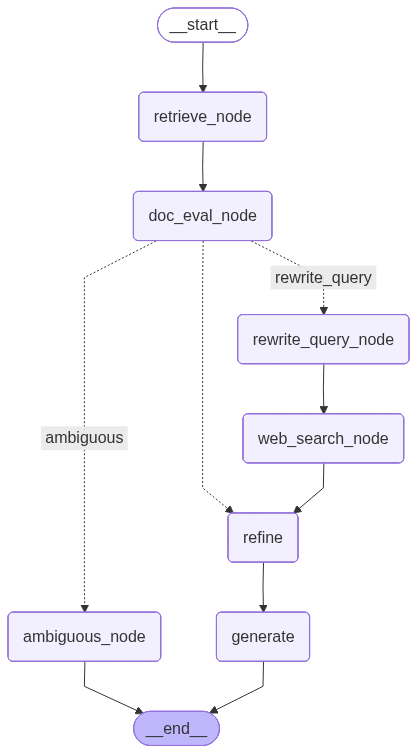

In [ ]:
app

In [ ]:
res = app.invoke(
    {
        "question": "explain KNN",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "web_docs": [], 
        "answer": "",
    }
)

In [ ]:
print(res['web_docs'])
print(res['answer'])
print()


[Document(metadata={'url': 'https://www.youtube.com/watch?v=v5CcxPiYSlA', 'title': 'K Nearest Neighbors (KNN) in 10 Minutes (Beginner Friendly)'}, page_content='TITLE: K Nearest Neighbors (KNN) in 10 Minutes (Beginner Friendly)\nURL: https://www.youtube.com/watch?v=v5CcxPiYSlA\nCONTENT:\n# K Nearest Neighbors (KNN) in 10 Minutes (Beginner Friendly)\n## Prof. Ryan Ahmed\n266000 subscribers\n305 likes\n\n### Description\n30877 views\nPosted: 25 Sep 2022\nK-Nearest Neighbors (KNN) algorithm is a classification algorithm\nthat works by finding the most similar data points in the training data, and attempt to make an educated guess based on their classifications\n\nThe algorithm follows these steps: \n\n1. Select a value for k (e.g.: 1, 2, 3, …..)\n2. Calculate the Euclidian distance between the point to be classified and every other point in the training data set\n3. Pick the k closest data points (points with the k smallest distances)\n4. Run a majority cote among selected data points, th